In [1]:
!git clone https://github.com/yanx27/Pointnet_Pointnet2_pytorch.git
%cd Pointnet_Pointnet2_pytorch
!pip install -q trimesh

Cloning into 'Pointnet_Pointnet2_pytorch'...
remote: Enumerating objects: 842, done.
remote: Total 842 (delta 0), reused 0 (delta 0), pack-reused 842 (from 1)
Receiving objects: 100% (842/842), 68.77 MiB | 25.89 MiB/s, done.
Resolving deltas: 100% (485/485), done.
/content/Pointnet_Pointnet2_pytorch


In [2]:
import os
import urllib.request
import zipfile

# Download the official ModelNet10 3D CAD dataset (~450 MB)
url = "http://3dvision.princeton.edu/projects/2014/3DShapeNets/ModelNet10.zip"
zip_path = "ModelNet10.zip"

if not os.path.exists("ModelNet10"):
    print("Downloading ModelNet10 3D CAD dataset...")
    urllib.request.urlretrieve(url, zip_path)
    print("Extracting files...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(".")
    os.remove(zip_path)
    print("Done! Dataset ready in ./ModelNet10")
else:
    print("ModelNet10 already exists!")

# Verify the CAD object categories
classes = sorted([d for d in os.listdir("ModelNet10") if os.path.isdir(os.path.join("ModelNet10", d)) and not d.startswith("__")])
print(f"Found {len(classes)} 3D CAD classes:", classes)

Extracting files...
Done! Dataset ready in ./ModelNet10
Found 10 3D CAD classes: ['bathtub', 'bed', 'chair', 'desk', 'dresser', 'monitor', 'night_stand', 'sofa', 'table', 'toilet']


In [3]:
import glob
import numpy as np
import trimesh
import torch
from torch.utils.data import TensorDataset, DataLoader
from tqdm import tqdm

NUM_POINTS = 1024
DATA_DIR = "ModelNet10"
classes = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)) and not d.startswith("__")])
class_to_idx = {cls: i for i, cls in enumerate(classes)}

def load_and_sample_split(split="train"):
    points_list, labels_list = [], []
    files = []
    for cls in classes:
        split_dir = os.path.join(DATA_DIR, cls, split)
        for f in glob.glob(os.path.join(split_dir, "*.off")):
            files.append((f, class_to_idx[cls]))

    print(f"Sampling {NUM_POINTS} points per 3D CAD mesh for '{split}' ({len(files)} models)...")
    for path, label in tqdm(files):
        mesh = trimesh.load(path, force='mesh')
        pts, _ = trimesh.sample.sample_surface(mesh, NUM_POINTS)

        # Center at origin and normalize to unit sphere
        pts = pts - np.mean(pts, axis=0)
        max_dist = np.max(np.linalg.norm(pts, axis=1))
        if max_dist > 0:
            pts = pts / max_dist

        points_list.append(pts)
        labels_list.append(label)

    return torch.tensor(np.array(points_list), dtype=torch.float32), torch.tensor(labels_list, dtype=torch.long)

train_pts, train_labels = load_and_sample_split("train")
test_pts, test_labels = load_and_sample_split("test")

train_loader = DataLoader(TensorDataset(train_pts, train_labels), batch_size=32, shuffle=True, drop_last=True)
test_loader = DataLoader(TensorDataset(test_pts, test_labels), batch_size=32, shuffle=False)

print(f"\nReady! Train shape: {train_pts.shape} | Test shape: {test_pts.shape}")

Sampling 1024 points per 3D CAD mesh for 'train' (3991 models)...


100%|██████████| 3991/3991 [03:55<00:00, 16.97it/s]


Sampling 1024 points per 3D CAD mesh for 'test' (908 models)...


100%|██████████| 908/908 [00:42<00:00, 21.16it/s]


Ready! Train shape: torch.Size([3991, 1024, 3]) | Test shape: torch.Size([908, 1024, 3])


In [4]:
import sys
sys.path.append('./models')
import pointnet2_cls_ssg as model_def

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = len(classes)

# normal_channel=False since input points have (x, y, z) coordinates only
classifier = model_def.get_model(num_classes, normal_channel=False).to(device)
criterion = model_def.get_loss().to(device)
optimizer = torch.optim.Adam(classifier.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

def augment_point_cloud(pts):
    # Random rotation around Z-axis (up-axis) + slight jitter
    theta = torch.rand(pts.size(0), device=pts.device) * 2 * np.pi
    cos_t, sin_t = torch.cos(theta), torch.sin(theta)
    rot = torch.zeros((pts.size(0), 3, 3), device=pts.device)
    rot[:, 0, 0] = cos_t
    rot[:, 0, 1] = -sin_t
    rot[:, 1, 0] = sin_t
    rot[:, 1, 1] = cos_t
    rot[:, 2, 2] = 1.0
    pts = torch.bmm(pts, rot)
    pts = pts + torch.randn_like(pts) * 0.01
    return pts

EPOCHS = 15
best_test_acc = 0.0
history = {"train_acc": [], "test_acc": [], "train_loss": []}

for epoch in range(1, EPOCHS + 1):
    classifier.train()
    total_loss, correct, total = 0.0, 0, 0
    for points, target in train_loader:
        points, target = points.to(device), target.to(device)
        points = augment_point_cloud(points)
        points = points.transpose(2, 1)  # Shape: (Batch, 3, 1024)

        optimizer.zero_grad()
        pred, trans_feat = classifier(points)
        loss = criterion(pred, target, trans_feat)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        correct += (pred.argmax(dim=1) == target).sum().item()
        total += target.size(0)

    scheduler.step()
    train_acc = 100.0 * correct / total

    # Evaluate on unseen test CAD models
    classifier.eval()
    test_correct, test_total = 0, 0
    with torch.no_grad():
        for points, target in test_loader:
            points, target = points.to(device), target.to(device)
            points = points.transpose(2, 1)
            pred, _ = classifier(points)
            test_correct += (pred.argmax(dim=1) == target).sum().item()
            test_total += target.size(0)

    test_acc = 100.0 * test_correct / test_total
    history["train_loss"].append(total_loss / len(train_loader))
    history["train_acc"].append(train_acc)
    history["test_acc"].append(test_acc)

    if test_acc > best_test_acc:
        best_test_acc = test_acc
        torch.save(classifier.state_dict(), "best_pointnet2_cad.pth")

    print(f"Epoch {epoch:02d}/{EPOCHS} | Loss: {total_loss/len(train_loader):.4f} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")

print(f"\nTraining complete! Best Test Accuracy: {best_test_acc:.2f}%")

Epoch 01/15 | Loss: 0.8951 | Train Acc: 70.94% | Test Acc: 67.73%
Epoch 02/15 | Loss: 0.5348 | Train Acc: 82.36% | Test Acc: 78.30%
Epoch 03/15 | Loss: 0.4413 | Train Acc: 84.95% | Test Acc: 80.07%
Epoch 04/15 | Loss: 0.3792 | Train Acc: 87.32% | Test Acc: 82.93%
Epoch 05/15 | Loss: 0.3505 | Train Acc: 88.00% | Test Acc: 81.61%
Epoch 06/15 | Loss: 0.2720 | Train Acc: 90.75% | Test Acc: 85.68%
Epoch 07/15 | Loss: 0.2298 | Train Acc: 92.39% | Test Acc: 87.11%
Epoch 08/15 | Loss: 0.2137 | Train Acc: 92.82% | Test Acc: 87.89%
Epoch 09/15 | Loss: 0.2167 | Train Acc: 92.34% | Test Acc: 85.90%
Epoch 10/15 | Loss: 0.2031 | Train Acc: 92.89% | Test Acc: 86.78%
Epoch 11/15 | Loss: 0.1720 | Train Acc: 93.98% | Test Acc: 87.89%
Epoch 12/15 | Loss: 0.1640 | Train Acc: 94.23% | Test Acc: 88.33%
Epoch 13/15 | Loss: 0.1465 | Train Acc: 94.61% | Test Acc: 88.99%
Epoch 14/15 | Loss: 0.1443 | Train Acc: 94.68% | Test Acc: 89.21%
Epoch 15/15 | Loss: 0.1489 | Train Acc: 94.88% | Test Acc: 88.44%

Training 

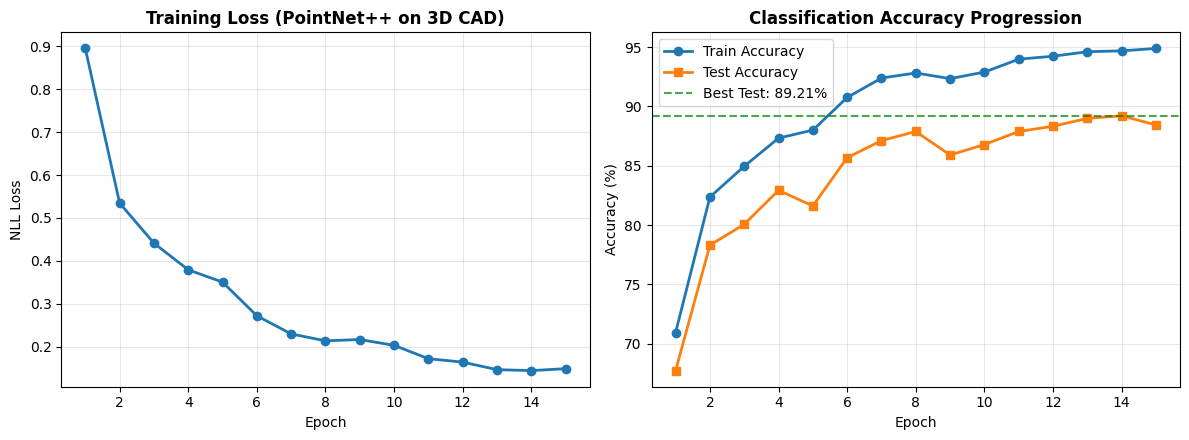

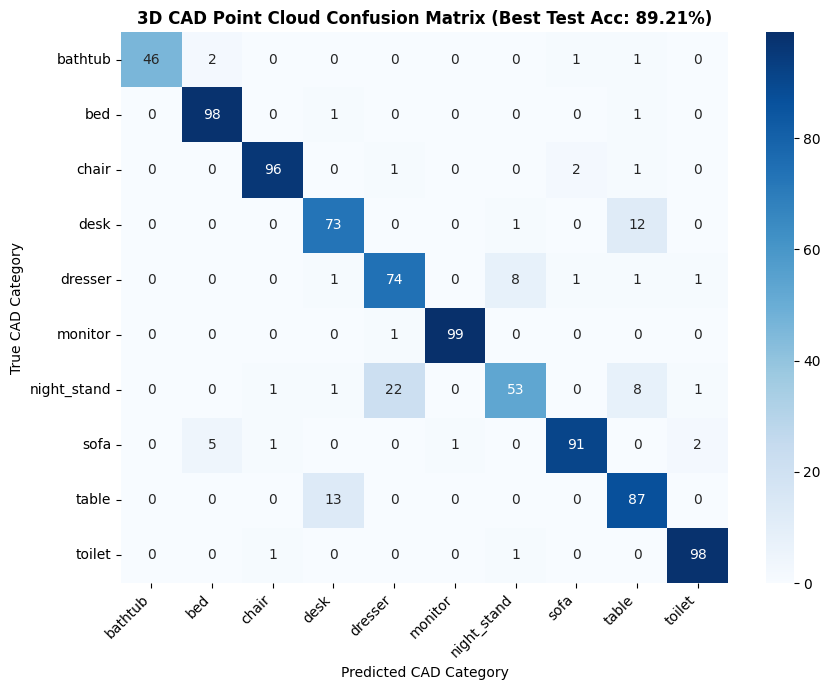

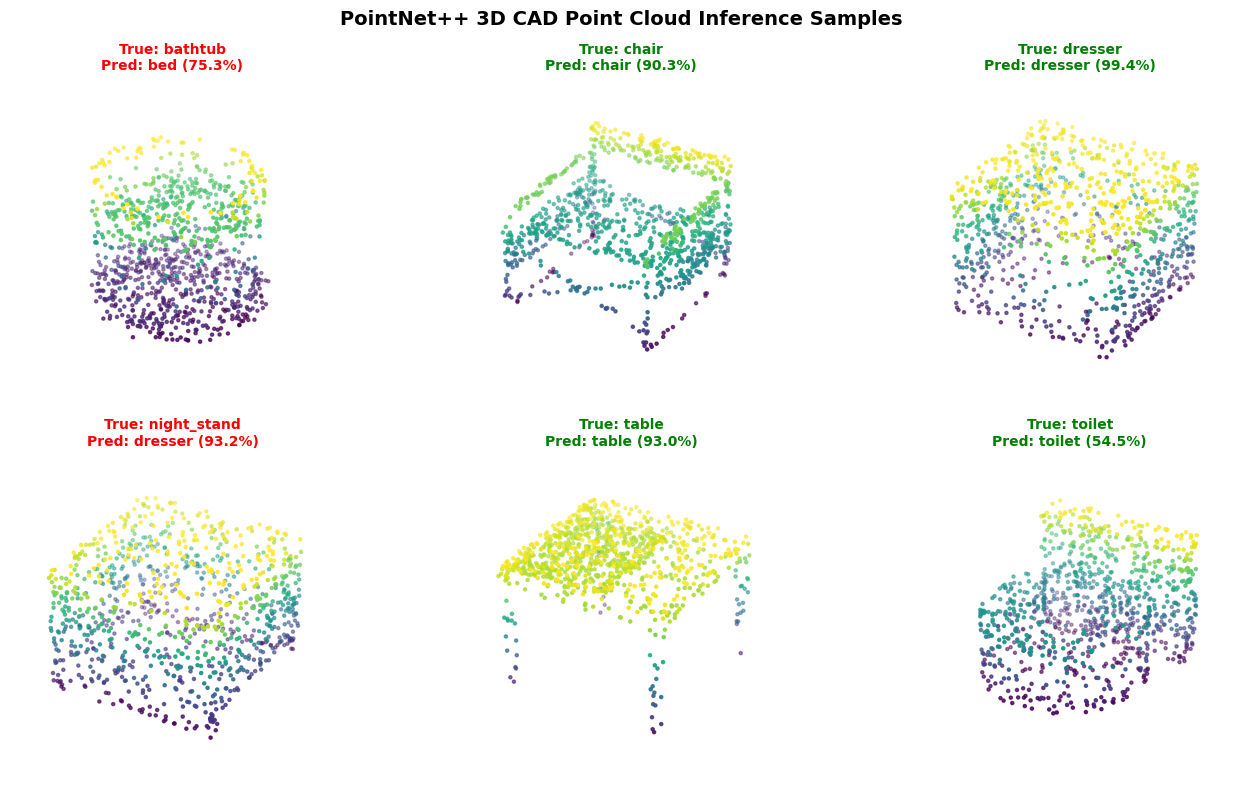

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import torch.nn.functional as F

# Load best model checkpoint
classifier.load_state_dict(torch.load("best_pointnet2_cad.pth"))
classifier.eval()

all_preds, all_targets, all_probs = [], [], []
with torch.no_grad():
    for points, target in test_loader:
        points = points.to(device).transpose(2, 1)
        pred, _ = classifier(points)
        probs = F.softmax(pred, dim=1)
        all_preds.extend(pred.argmax(dim=1).cpu().numpy())
        all_targets.extend(target.numpy())
        all_probs.extend(probs.max(dim=1)[0].cpu().numpy())

# 1. Plot Training & Validation Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
epochs_range = range(1, EPOCHS + 1)

ax1.plot(epochs_range, history["train_loss"], marker='o', color='#1f77b4', linewidth=2)
ax1.set_title("Training Loss (PointNet++ on 3D CAD)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Epoch")
ax1.set_ylabel("NLL Loss")
ax1.grid(True, alpha=0.3)

ax2.plot(epochs_range, history["train_acc"], marker='o', label="Train Accuracy", linewidth=2)
ax2.plot(epochs_range, history["test_acc"], marker='s', label="Test Accuracy", linewidth=2)
ax2.axhline(best_test_acc, color='green', linestyle='--', alpha=0.7, label=f"Best Test: {best_test_acc:.2f}%")
ax2.set_title("Classification Accuracy Progression", fontsize=12, fontweight='bold')
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=200)
plt.show()

# 2. Plot Confusion Matrix
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title(f"3D CAD Point Cloud Confusion Matrix (Best Test Acc: {best_test_acc:.2f}%)", fontsize=12, fontweight='bold')
plt.xlabel("Predicted CAD Category")
plt.ylabel("True CAD Category")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)
plt.show()

# 3. Plot 3D Point Cloud Sample Predictions (2x3 Grid)
sample_indices = np.linspace(0, len(test_pts) - 1, 6, dtype=int)
fig = plt.figure(figsize=(14, 8))

for i, idx in enumerate(sample_indices):
    pts = test_pts[idx].numpy()
    true_cls = classes[all_targets[idx]]
    pred_cls = classes[all_preds[idx]]
    conf = all_probs[idx] * 100
    color = "green" if true_cls == pred_cls else "red"

    ax = fig.add_subplot(2, 3, i + 1, projection='3d')
    ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=5, c=pts[:, 2], cmap='viridis')
    ax.set_title(f"True: {true_cls}\nPred: {pred_cls} ({conf:.1f}%)", color=color, fontsize=10, fontweight='bold')
    ax.set_axis_off()

plt.suptitle("PointNet++ 3D CAD Point Cloud Inference Samples", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("cad_predictions_grid.png", dpi=200)
plt.show()

In [6]:
from google.colab import files

for fname in ["training_curves.png", "confusion_matrix.png", "cad_predictions_grid.png", "best_pointnet2_cad.pth"]:
    files.download(fname)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>